In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import numpy as np

# Load the dataset
df = pd.read_csv('Beauty_dataset_amazon.csv', sep=';', low_memory=False, encoding='latin1')

# Initial inspection
print("--- Data Info ---")
print(df.info())
print("\n--- Data Head ---")
print(df.head())
print("\n--- Summary Statistics ---")
print(df.describe(include='all'))

# Remove empty columns if any (based on snippet there are many empty semicolons at the end)
df = df.dropna(axis=1, how='all')

# Re-inspect after dropping empty columns
print("\n--- Cleaned Columns Info ---")
print(df.info())

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 473823 entries, 0 to 473822
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   rating             473810 non-null  object
 1   title              473738 non-null  object
 2   text               470534 non-null  object
 3   images             458016 non-null  object
 4   asin               457987 non-null  object
 5   parent_asin        457981 non-null  object
 6   user_id            457973 non-null  object
 7   timestamp          457962 non-null  object
 8   helpful_vote       457891 non-null  object
 9   verified_purchase  457835 non-null  object
 10  Unnamed: 10        51 non-null      object
 11  Unnamed: 11        36 non-null      object
 12  Unnamed: 12        31 non-null      object
 13  Unnamed: 13        22 non-null      object
 14  Unnamed: 14        20 non-null      object
 15  Unnamed: 15        17 non-null      object
 16  Un

In [ ]:
import pandas as pd

# 1. Load Data
df = pd.read_csv('Beauty_dataset_amazon.csv', delimiter=';', on_bad_lines='skip', encoding='latin1')

# 2. Cleaning: Hapus baris yang kolom 'helpful_vote'-nya kosong (rusak)
df_clean = df.dropna(subset=['helpful_vote', 'text']).copy() # Added .copy() to prevent SettingWithCopyWarning

# Convert helpful_vote to numeric, coercing errors to NaN, then fill NaN with 0 and convert to int
df_clean['helpful_vote'] = pd.to_numeric(df_clean['helpful_vote'], errors='coerce').fillna(0).astype(int)

# 3. Labeling sesuai Metodologi (Helpful jika vote > 2)
# Label 1 = Helpful, Label 0 = Not Helpful
df_clean['label'] = df_clean['helpful_vote'].apply(lambda x: 1 if x > 2 else 0)

# 4. Stratified Balancing (Menyeimbangkan jumlah data ke sekitar 50,000)
# Target jumlah sampel per kelas
target_samples_per_class = 25000

# Ambil data Helpful dengan jumlah yang sesuai target
data_helpful = df_clean[df_clean['label'] == 1].sample(n=min(len(df_clean[df_clean['label'] == 1]), target_samples_per_class), random_state=42)

# Ambil data Not Helpful dengan jumlah yang SAMA persis
data_not_helpful = df_clean[df_clean['label'] == 0].sample(n=len(data_helpful), random_state=42)

# Gabungkan kembali
df_final = pd.concat([data_helpful, data_not_helpful])

# Acak urutan baris
df_final = df_final.sample(frac=1, random_state=42).reset_index(drop=True)

# 5. Cek Hasil Akhir
print(f"Total Data Final: {len(df_final)}")
print(f"Jumlah Helpful: {len(df_final[df_final['label']==1])}")
print(f"Jumlah Not Helpful: {len(df_final[df_final['label']==0])}")


df_final[['text', 'label']].to_csv('Beauty_dataset_50k.csv', index=False)

/tmp/ipython-input-2772527215.py:4: DtypeWarning: Columns (0,8,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Beauty_dataset_amazon.csv', delimiter=';', on_bad_lines='skip', encoding='latin1')


Total Data Final: 50000
Jumlah Helpful: 25000
Jumlah Not Helpful: 25000


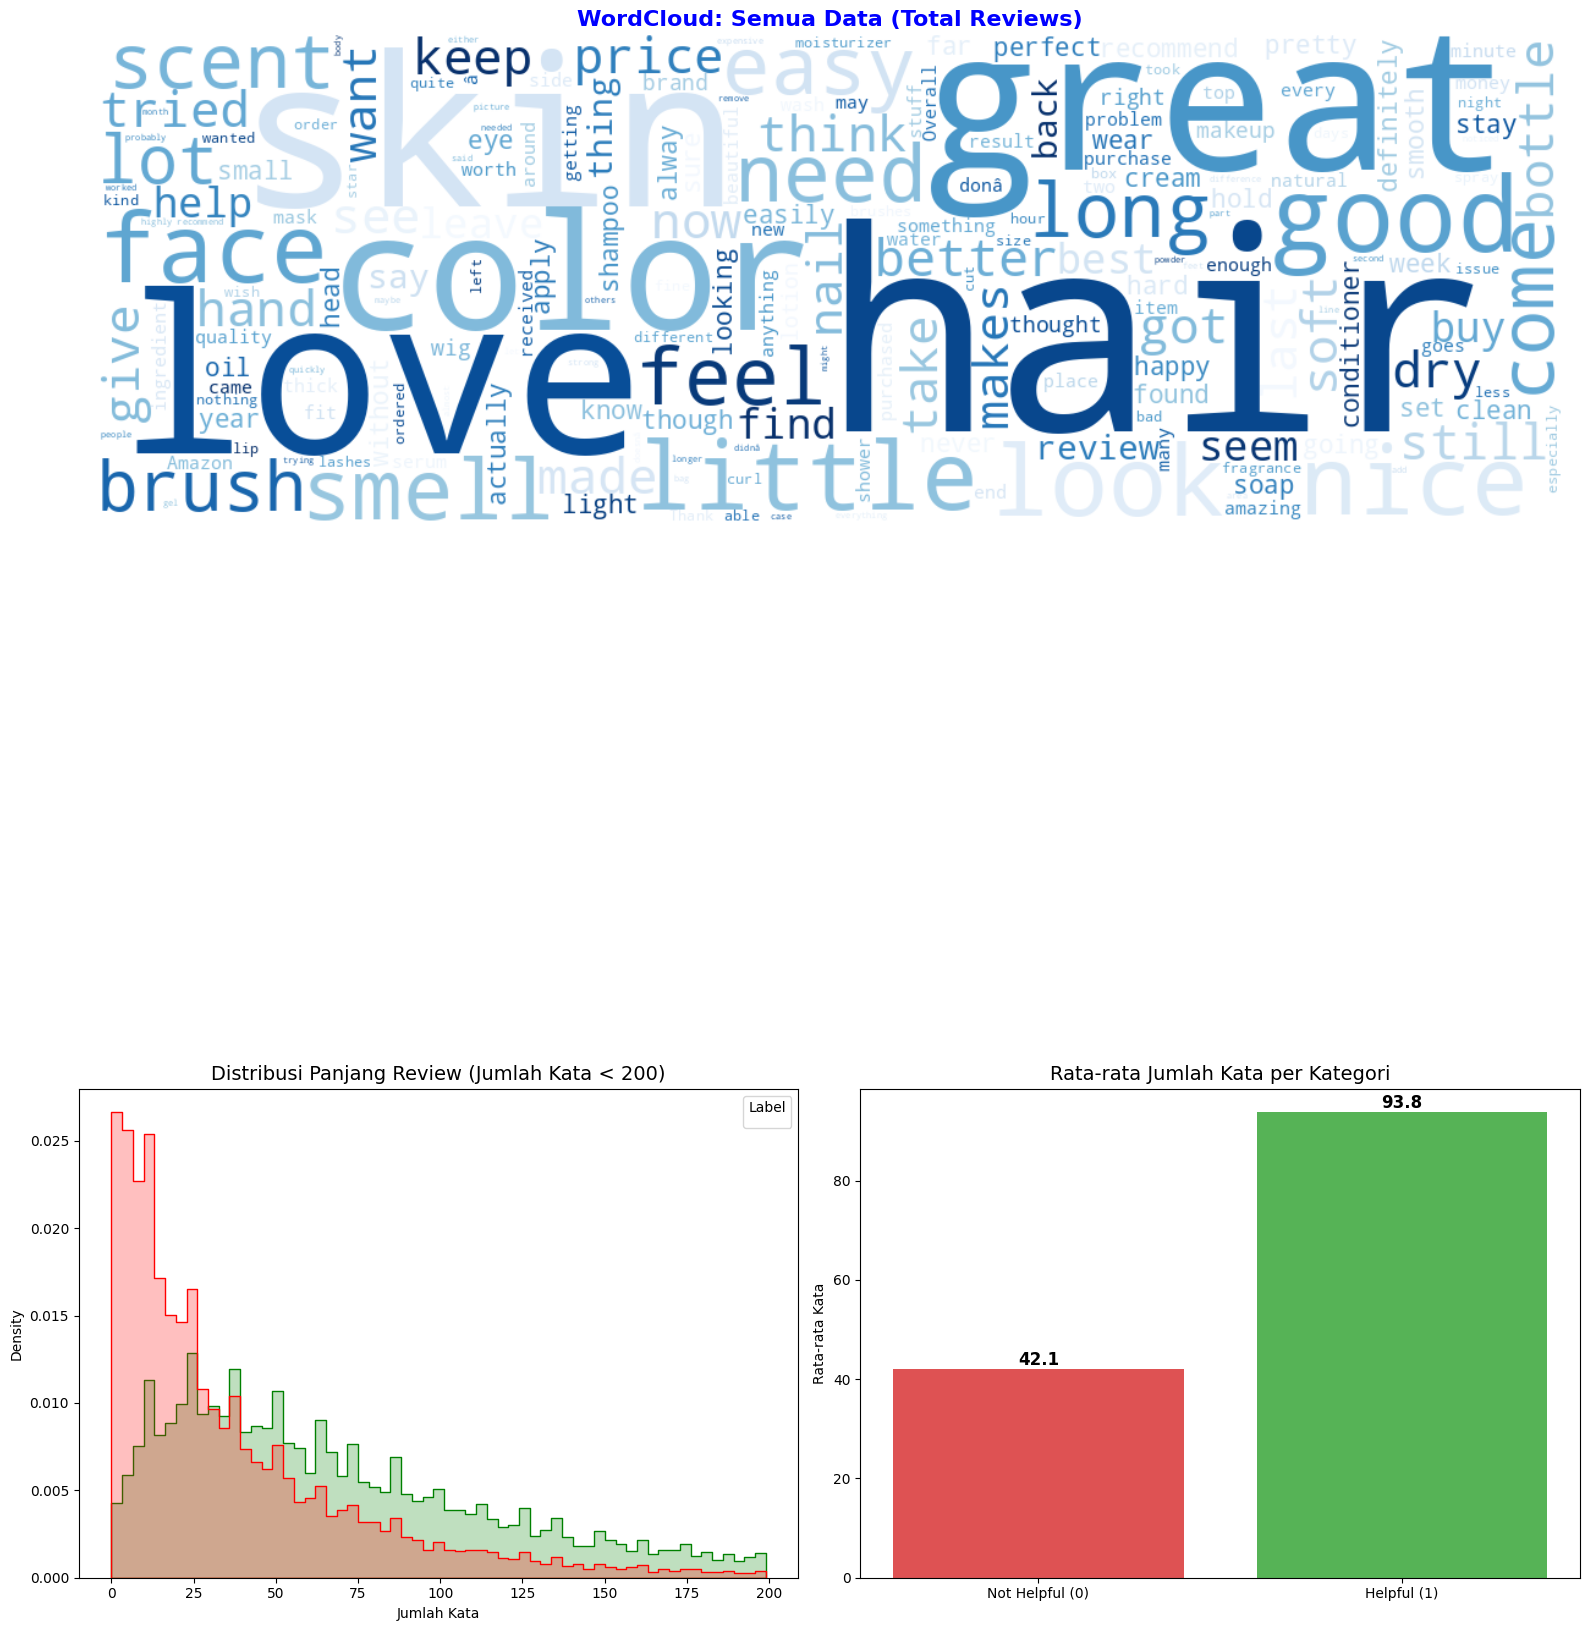

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
import seaborn as sns
import numpy as np
from matplotlib.gridspec import GridSpec

# ==========================================
# 1. DATA PREPARATION (Cleaning & Balancing)
# ==========================================

# Load Dataset
try:
    df = pd.read_csv('Beauty_dataset_50k.csv')
except Exception:
    df = pd.read_csv('Beauty_dataset_50k.csv', header=None, names=['combined_column'])

df_final = df.copy()

# Explicitly handle cases where 'text' and 'label' are combined
if 'text,label' in df_final.columns and len(df_final.columns) == 1:
    df_final[['text', 'label']] = df_final['text,label'].str.split(',', n=1, expand=True)
    df_final = df_final.drop(columns=['text,label'])
elif 'combined_column' in df_final.columns and len(df_final.columns) == 1:
    if ',' in str(df_final.loc[0, 'combined_column']):
        header_names = df_final.loc[0, 'combined_column'].split(',', 1)
        df_final[['text', 'label']] = df_final['combined_column'].iloc[1:].str.split(',', n=1, expand=True)
        df_final.columns = header_names
        df_final = df_final.reset_index(drop=True)
    else:
        df_final[['text', 'label']] = df_final['combined_column'].str.split(',', n=1, expand=True)
    df_final = df_final.drop(columns=['combined_column'], errors='ignore')

# Ensure types
df_final['label'] = df_final['label'].astype(int)
df_final['text'] = df_final['text'].astype(str)

# Calculate word count
df_final['word_count'] = df_final['text'].apply(lambda x: len(str(x).split()))

# ==========================================
# 2. VISUALIZATION (Updated with Stopwords)
# ==========================================

# --- KONFIGURASI STOPWORDS ---
# 1. Ambil list default stopwords bahasa Inggris
final_stopwords = set(STOPWORDS)

# 2. (Opsional tapi Direkomendasikan) Tambahkan kata-kata 'sampah' spesifik dataset Beauty/Review
# Kata-kata ini sering muncul tapi tidak memberikan insight sentimen
custom_new_words = custom_words = {
    "br",
    "t", "s", "m", "ve", "re", "ll", "don",
    "iâ", "itâ",
    "product", "products",
    "one",
    "will",
    "really", "much", "even", "well",
    "day", "time", "first", "way", "bit",
    "use", "used", "using",
    "make", "put", "work", "works", "go", "try", "bought",
    "the", "and", "to", "of", "a", "in", "is", "it", "that", "for", "i", "this", "on", "with", "was", "my", "but", "as", "have", "not", "be", "are", "you", "so", "it's"
}
final_stopwords.update(custom_new_words)
# -----------------------------

# Prepare text strings
text_all = " ".join(review for review in df_final['text'].astype(str))
text_helpful = " ".join(review for review in df_final[df_final['label'] == 1]['text'].astype(str))
text_not_helpful = " ".join(review for review in df_final[df_final['label'] == 0]['text'].astype(str))

# Create figure
fig = plt.figure(figsize=(16, 18))
gs = GridSpec(3, 2, figure=fig)
fig.suptitle('', fontsize=22, weight='bold')

# --- PLOT 1: WordCloud All Data ---
ax0 = fig.add_subplot(gs[0, :])
# Tambahkan parameter stopwords=final_stopwords
wc_all = WordCloud(width=1200, height=400, background_color='white',
                   colormap='Blues', stopwords=final_stopwords).generate(text_all)
ax0.imshow(wc_all, interpolation='bilinear')
ax0.set_title('WordCloud: Semua Data (Total Reviews)', fontsize=16, color='blue', weight='bold')
ax0.axis('off')


# --- PLOT 4: Histogram ---
ax3 = fig.add_subplot(gs[2, 0])
sns.histplot(data=df_final[df_final['word_count'] < 200], x='word_count', hue='label',
             element="step", stat="density", common_norm=False, ax=ax3, palette=['red', 'green'])
ax3.set_title('Distribusi Panjang Review (Jumlah Kata < 200)', fontsize=14)
ax3.set_xlabel('Jumlah Kata')
ax3.set_ylabel('Density')
handles, labels = ax3.get_legend_handles_labels()
ax3.legend(handles, ['Not Helpful', 'Helpful'], title='Label')

# --- PLOT 5: Bar Chart ---
ax4 = fig.add_subplot(gs[2, 1])
avg_words = df_final.groupby('label')['word_count'].mean()
colors = ['#d62728', '#2ca02c']
bars = ax4.bar(['Not Helpful (0)', 'Helpful (1)'], avg_words, color=colors, alpha=0.8)
ax4.set_title('Rata-rata Jumlah Kata per Kategori', fontsize=14)
ax4.set_ylabel('Rata-rata Kata')

for bar in bars:
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}',
             ha='center', va='bottom', fontsize=12, weight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])



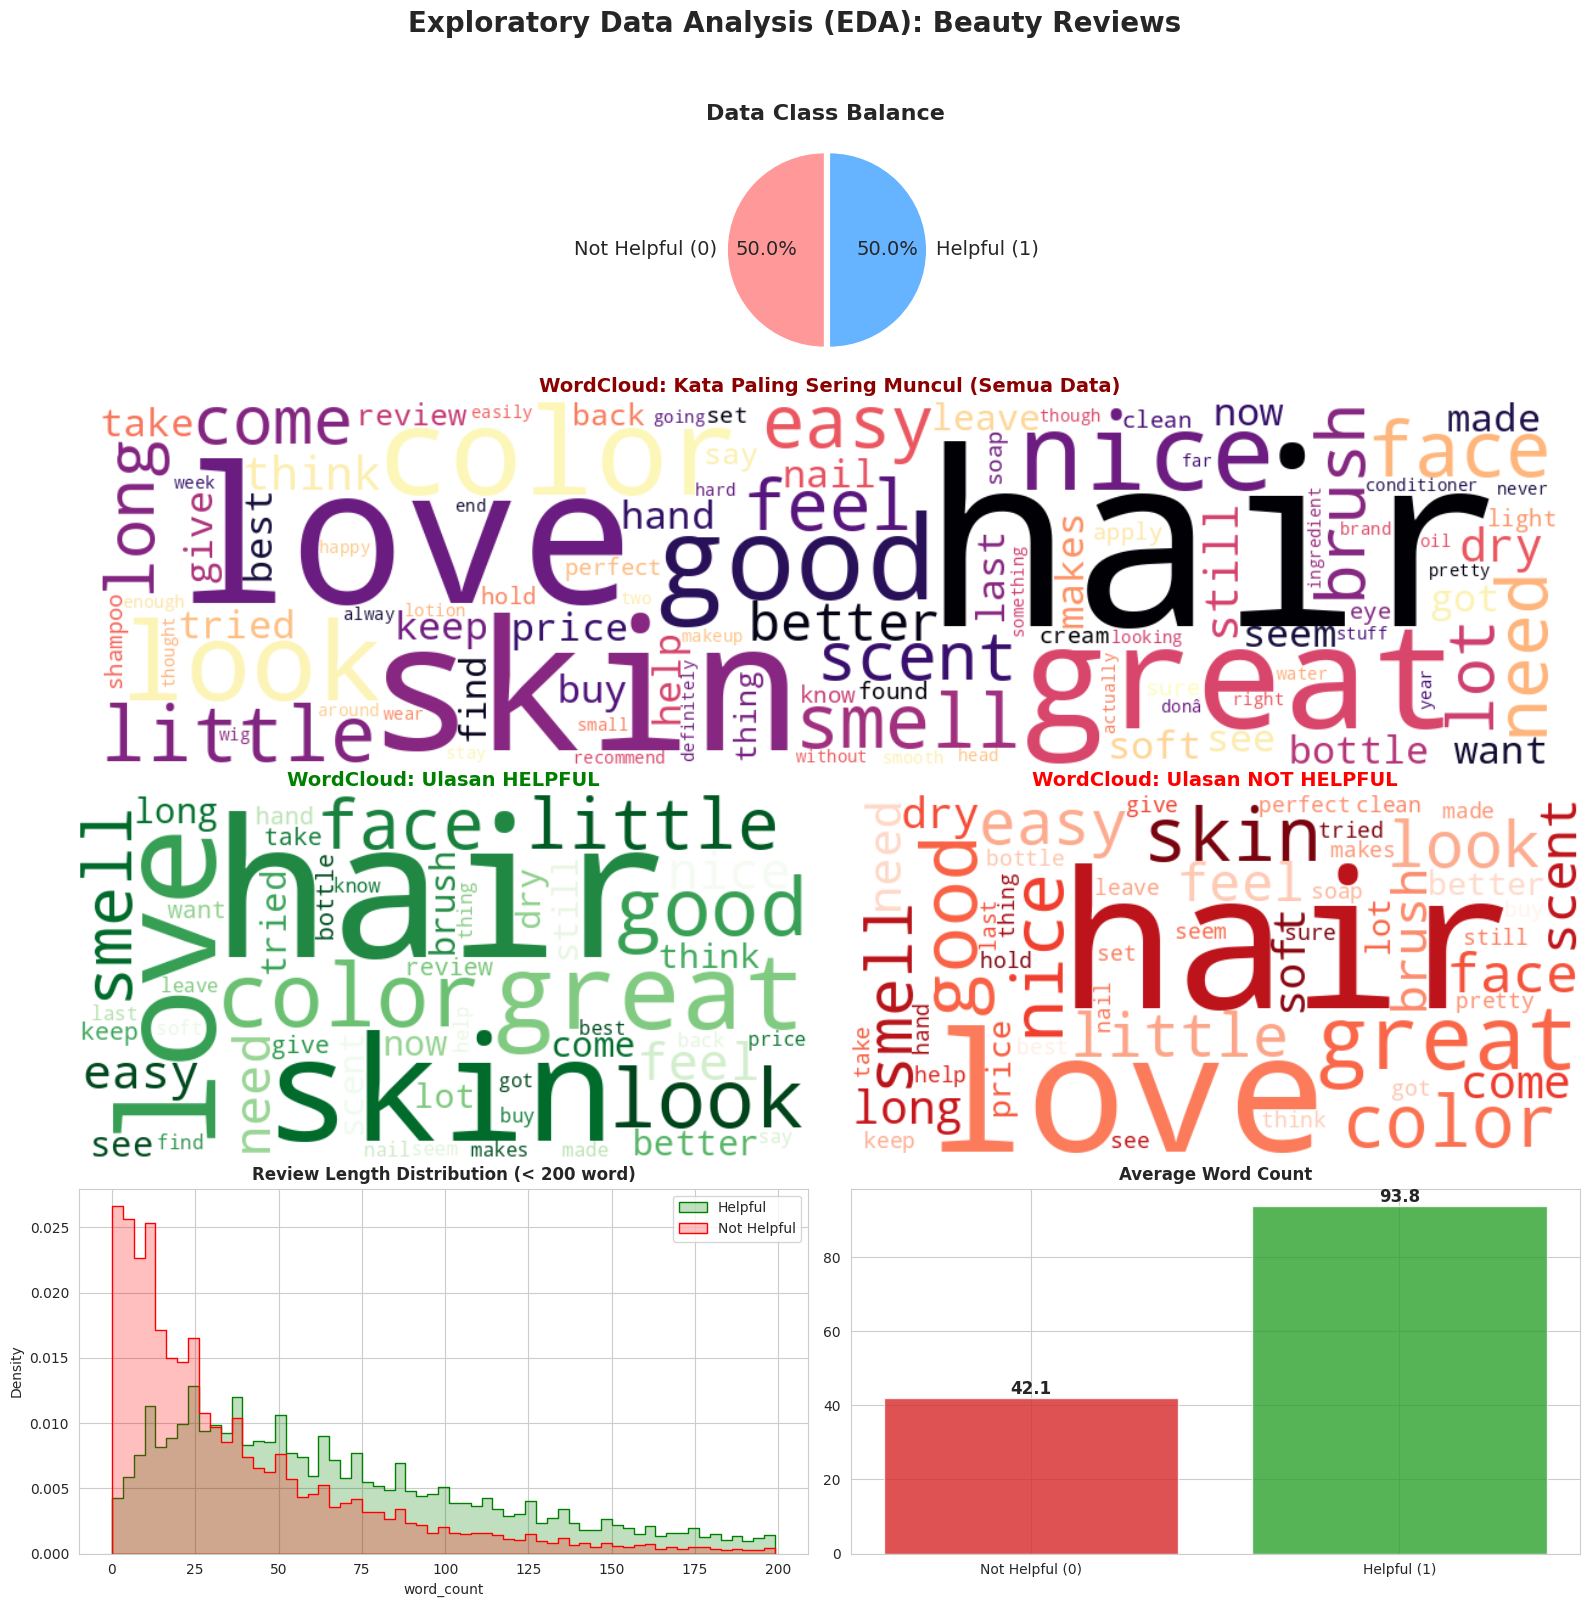

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
import seaborn as sns
import numpy as np
from matplotlib.gridspec import GridSpec

# ==========================================
# 1. DATA PREPARATION
# ==========================================
# Load Dataset
try:
    df = pd.read_csv('Beauty_dataset_50k.csv')
except Exception:
    # Fallback jika format error
    df = pd.read_csv('Beauty_dataset_50k.csv', header=None, names=['combined_column'])

df_final = df.copy()

# Cleaning kolom jika tergabung
if 'text,label' in df_final.columns and len(df_final.columns) == 1:
    df_final[['text', 'label']] = df_final['text,label'].str.split(',', n=1, expand=True)
    df_final = df_final.drop(columns=['text,label'])
elif 'combined_column' in df_final.columns and len(df_final.columns) == 1:
    # Deteksi header
    if ',' in str(df_final.loc[0, 'combined_column']):
        header_names = df_final.loc[0, 'combined_column'].split(',', 1)
        df_final[['text', 'label']] = df_final['combined_column'].iloc[1:].str.split(',', n=1, expand=True)
        df_final.columns = header_names
        df_final = df_final.reset_index(drop=True)
    else:
        df_final[['text', 'label']] = df_final['combined_column'].str.split(',', n=1, expand=True)
    df_final = df_final.drop(columns=['combined_column'], errors='ignore')

# Pastikan tipe data benar
df_final['label'] = pd.to_numeric(df_final['label'], errors='coerce').fillna(0).astype(int)
df_final['text'] = df_final['text'].astype(str)

# Hitung jumlah kata
df_final['word_count'] = df_final['text'].apply(lambda x: len(str(x).split()))

# ==========================================
# 2. VISUALIZATION (FULL EDA)
# ==========================================

# --- CONFIG STOPWORDS ---
final_stopwords = set(STOPWORDS)
custom_words = {
        "br",
    "t", "s", "m", "ve", "re", "ll", "don",
    "iâ", "itâ",
    "product", "products",
    "one",
    "will",
    "really", "much", "even", "well",
    "day", "time", "first", "way", "bit",
    "use", "used", "using",
    "make", "put", "work", "works", "go", "try", "bought",
    "the", "and", "to", "of", "a", "in", "is", "it", "that", "for", "i", "this", "on", "with", "was", "my", "but", "as", "have", "not", "be", "are", "you", "so", "it's"
}
final_stopwords.update(custom_words)

# --- PREPARE TEXT ---
text_all = " ".join(review for review in df_final['text'])
text_helpful = " ".join(review for review in df_final[df_final['label'] == 1]['text'])
text_not_helpful = " ".join(review for review in df_final[df_final['label'] == 0]['text'])

# --- SETUP FIGURE ---
fig = plt.figure(figsize=(16, 18))
# Layout: 4 Baris
# Baris 0: Pie Chart (Balance Check)
# Baris 1: WordCloud All
# Baris 2: WordCloud Per Class
# Baris 3: Statistik Panjang Kata
gs = GridSpec(4, 2, figure=fig, height_ratios=[1, 1.5, 1.5, 1.5])
fig.suptitle('Exploratory Data Analysis (EDA): Beauty Reviews', fontsize=20, weight='bold', y=0.92)

# --- PLOT 1: Class Balance (PENTING untuk membuktikan data seimbang) ---
ax0 = fig.add_subplot(gs[0, :])
label_counts = df_final['label'].value_counts()
colors_pie = ['#ff9999','#66b3ff']
ax0.pie(label_counts, labels=['Not Helpful (0)', 'Helpful (1)'], autopct='%1.1f%%',
        startangle=90, colors=colors_pie, explode=(0.05, 0), textprops={'fontsize': 14})
ax0.set_title('Data Class Balance ', fontsize=16, weight='bold')

# --- PLOT 2: WordCloud All Data ---
ax1 = fig.add_subplot(gs[1, :])
wc_all = WordCloud(width=1200, height=300, background_color='white', colormap='magma',
                   stopwords=final_stopwords, max_words=100).generate(text_all)
ax1.imshow(wc_all, interpolation='bilinear')
ax1.set_title('WordCloud: Kata Paling Sering Muncul (Semua Data)', fontsize=14, color='darkred', weight='bold')
ax1.axis('off')

# --- PLOT 3: WordCloud Helpful (Kiri) ---
ax2 = fig.add_subplot(gs[2, 0])
wc_help = WordCloud(width=600, height=300, background_color='white', colormap='Greens',
                    stopwords=final_stopwords, max_words=50).generate(text_helpful)
ax2.imshow(wc_help, interpolation='bilinear')
ax2.set_title('WordCloud: Ulasan HELPFUL', fontsize=14, color='green', weight='bold')
ax2.axis('off')

# --- PLOT 4: WordCloud Not Helpful (Kanan) ---
ax3 = fig.add_subplot(gs[2, 1])
wc_not = WordCloud(width=600, height=300, background_color='white', colormap='Reds',
                   stopwords=final_stopwords, max_words=50).generate(text_not_helpful)
ax3.imshow(wc_not, interpolation='bilinear')
ax3.set_title('WordCloud: Ulasan NOT HELPFUL', fontsize=14, color='red', weight='bold')
ax3.axis('off')

# --- PLOT 5: Distribusi Panjang Kata ---
ax4 = fig.add_subplot(gs[3, 0])
sns.histplot(data=df_final[df_final['word_count'] < 200], x='word_count', hue='label',
             element="step", stat="density", common_norm=False, ax=ax4, palette=['red', 'green'])
ax4.set_title('Review Length Distribution (< 200 word)', fontsize=12, weight='bold')
ax4.legend(labels=['Helpful', 'Not Helpful'])

# --- PLOT 6: Rata-rata Kata ---
ax5 = fig.add_subplot(gs[3, 1])
avg_words = df_final.groupby('label')['word_count'].mean()
bars = ax5.bar(['Not Helpful (0)', 'Helpful (1)'], avg_words, color=['#d62728', '#2ca02c'], alpha=0.8)
ax5.set_title('Average Word Count', fontsize=12, weight='bold')
for bar in bars:
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}',
             ha='center', va='bottom', fontsize=12, weight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.90]) # Adjust layout agar judul tidak terpotong
plt.show()

✅ Device: cuda (Tesla T4)
✅ Data Loaded: 50000 baris
⏳ Membagi data training & testing...
✅ Siap Training: 40000 data latih, 10000 data uji

🚀 MEMULAI TRAINING: BERT...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

... (12 outputs left out)

✅ Training Selesai: 662.51 detik


📊 Ukuran Model DistilBERT: 255.42 MB

=== RINGKASAN HASIL FINAL ===


,Model,F1-Score,Accuracy,Train_Time_Sec,Inference_Time_ms,Size_MB
0,BERT,0.697968,0.7086,1169.545414,1.386117,417.66
1,DistilBERT,0.693603,0.7035,662.506081,1.302253,255.42


/tmp/ipython-input-848773298.py:201: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x='Model', y='F1-Score', data=results_df, palette=['#1f77b4', '#ff7f0e'])


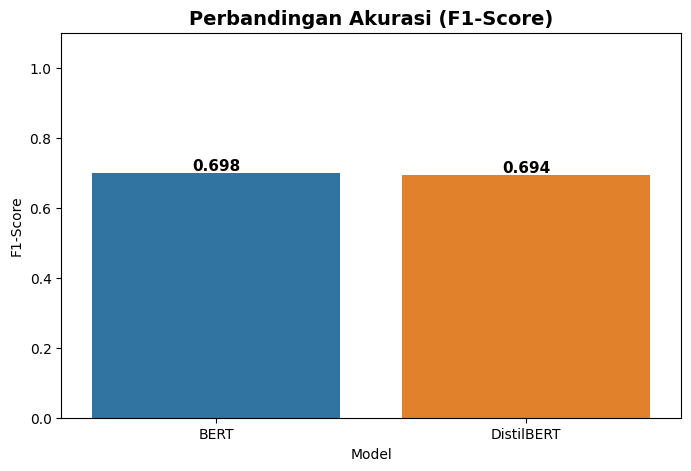

/tmp/ipython-input-848773298.py:212: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x='Model', y='Train_Time_Sec', data=results_df, palette=['#1f77b4', '#ff7f0e'])


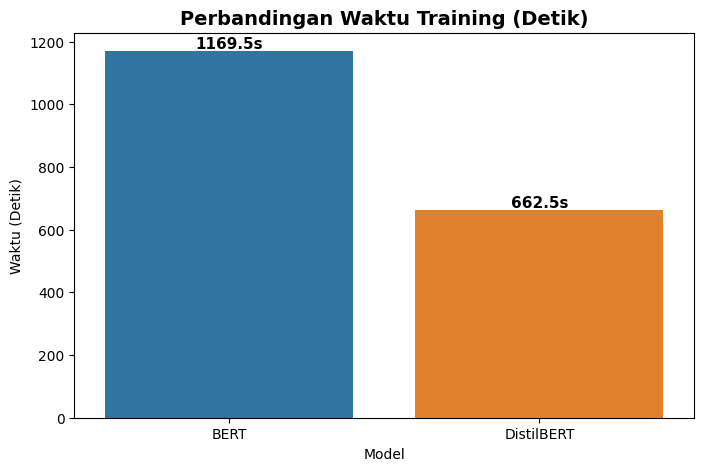

/tmp/ipython-input-848773298.py:222: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(x='Model', y='Inference_Time_ms', data=results_df, palette=['#1f77b4', '#ff7f0e'])


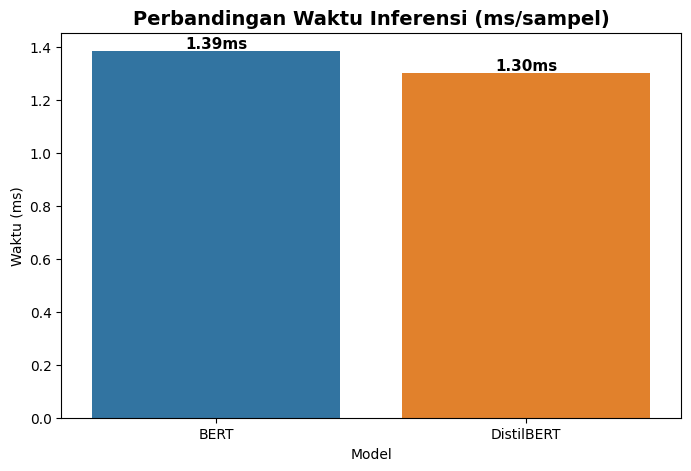

/tmp/ipython-input-848773298.py:232: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax4 = sns.barplot(x='Model', y='Size_MB', data=results_df, palette=['#1f77b4', '#ff7f0e'])


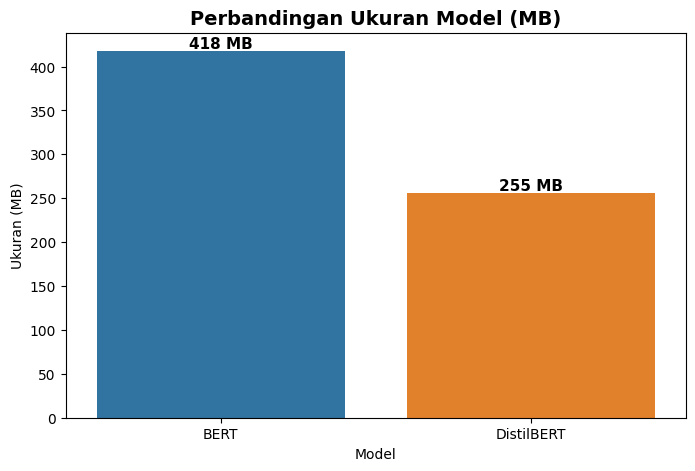

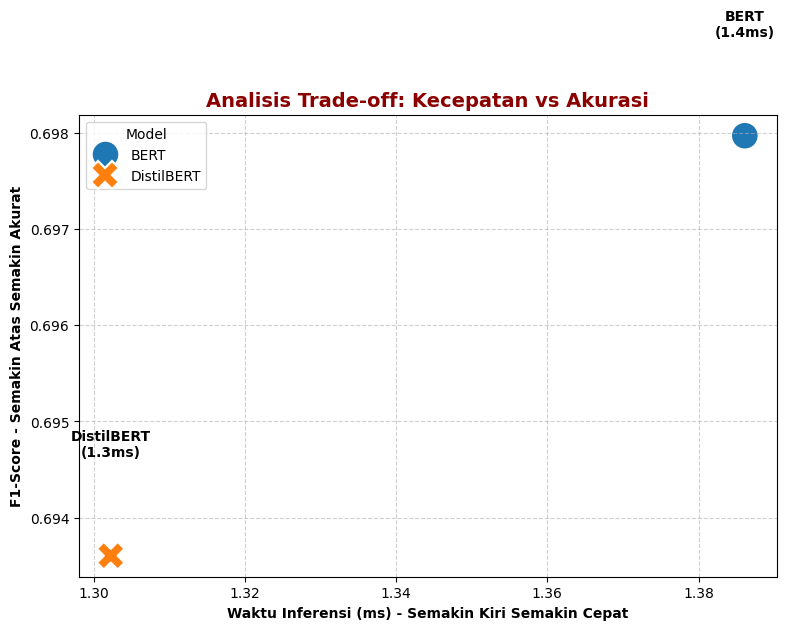

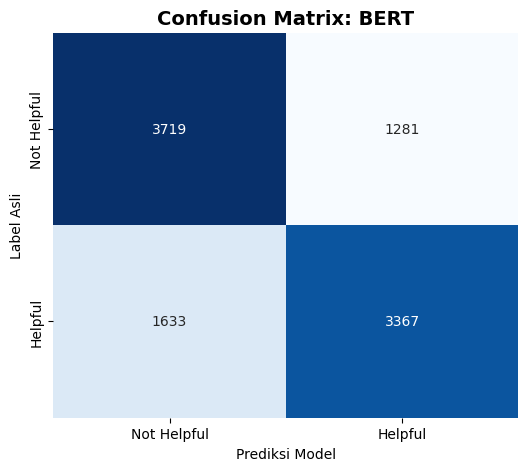

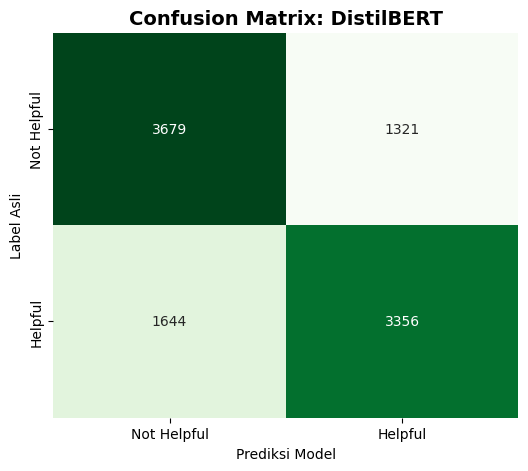

In [ ]:
# ==========================================
# 1. SETUP & IMPORT
# ==========================================
import os
# Mencegah error memori terfragmentasi
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

# Install library
!pip install transformers datasets scikit-learn pandas torch accelerate wordcloud -q

import pandas as pd
import numpy as np
import re
import torch
import time
import gc
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from transformers import (
    BertTokenizer, BertForSequenceClassification,
    DistilBertTokenizer, DistilBertForSequenceClassification,
    Trainer, TrainingArguments
)
from torch.utils.data import Dataset

# Cek Device
torch.cuda.empty_cache()
gc.collect()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ==========================================
# 2. LOAD DATA & SPLITTING (PENTING!)
# ==========================================
filename = 'Beauty_dataset_50k.csv'
try:
    df = pd.read_csv(filename)
    print(f"✅ Data Loaded: {len(df)} baris")
except FileNotFoundError:
    raise ValueError(f"❌ File '{filename}' belum di-upload!")

# Cleaning
def clean_text(text):
    if not isinstance(text, str): return ""
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['text'].apply(clean_text)

# --- DEFINISI X_TRAIN (Bagian yang tadi Error) ---
print("⏳ Membagi data training & testing...")
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label'],
    test_size=0.2, random_state=42, stratify=df['label']
)
print(f"✅ Siap Training: {len(X_train)} data latih, {len(X_test)} data uji")

# ==========================================
# 3. DATASET CLASS
# ==========================================
class ReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts.iloc[idx])
        label = self.labels.iloc[idx]
        encoding = self.tokenizer.encode_plus(
            text, add_special_tokens=True, max_length=self.max_len,
            padding='max_length', truncation=True, return_attention_mask=True, return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        'f1': f1_score(labels, predictions),
        'accuracy': accuracy_score(labels, predictions)
    }

# ==========================================
# 4. ENGINE TRAINING (Auto Size Calculation)
# ==========================================
def train_and_evaluate(model_name, X_train, y_train, X_test, y_test):
    print(f"\n🚀 MEMULAI TRAINING: {model_name}...")

    # Bersihkan Memori
    torch.cuda.empty_cache()
    gc.collect()

    # Pilih Model
    if model_name == 'BERT':
        ckpt = 'bert-base-uncased'
        tokenizer = BertTokenizer.from_pretrained(ckpt)
        model = BertForSequenceClassification.from_pretrained(ckpt, num_labels=2)
    else:
        ckpt = 'distilbert-base-uncased'
        tokenizer = DistilBertTokenizer.from_pretrained(ckpt)
        model = DistilBertForSequenceClassification.from_pretrained(ckpt, num_labels=2)

    model.to(device)
    train_ds = ReviewDataset(X_train, y_train, tokenizer)
    test_ds = ReviewDataset(X_test, y_test, tokenizer)

    args = TrainingArguments(
        output_dir=f'./results_{model_name}',
        num_train_epochs=2,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        fp16=True,
        eval_strategy="epoch",
        save_strategy="no",
        learning_rate=2e-5,
        report_to="none"
    )

    trainer = Trainer(
        model=model, args=args,
        train_dataset=train_ds, eval_dataset=test_ds,
        compute_metrics=compute_metrics
    )

    # 1. Training
    start = time.time()
    trainer.train()
    train_time = time.time() - start
    print(f"✅ Training Selesai: {train_time:.2f} detik")

    # 2. Evaluasi Metrik
    eval_res = trainer.evaluate()

    # 3. Hitung Size Model Secara OTOMATIS (Real-time)
    param_size = 0
    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    buffer_size = 0
    for buffer in model.buffers():
        buffer_size += buffer.nelement() * buffer.element_size()
    real_size_mb = (param_size + buffer_size) / 1024**2
    print(f"📊 Ukuran Model {model_name}: {real_size_mb:.2f} MB")

    # 4. Cek Kecepatan Inferensi
    sample_text = X_test.iloc[:1000].tolist()
    model.eval()
    t0 = time.time()
    with torch.no_grad():
        inputs = tokenizer(sample_text, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
        _ = model(**inputs)
    infer_time_ms = ((time.time() - t0) * 1000) / 1000

    # Confusion Matrix
    preds = trainer.predict(test_ds)
    cm = confusion_matrix(y_test, np.argmax(preds.predictions, axis=-1))

    # Bersihkan dari GPU
    del model, tokenizer, trainer
    torch.cuda.empty_cache()

    return {
        'Model': model_name,
        'F1-Score': eval_res['eval_f1'],
        'Accuracy': eval_res['eval_accuracy'],
        'Train_Time_Sec': train_time,
        'Inference_Time_ms': infer_time_ms,
        'CM': cm,
        'Size_MB': round(real_size_mb, 2) # Hasil perhitungan otomatis
    }

# ==========================================
# 5. EKSEKUSI & VISUALISASI TERPISAH
# ==========================================

# 1. Jalankan Eksperimen
bert_res = train_and_evaluate('BERT', X_train, y_train, X_test, y_test)
distil_res = train_and_evaluate('DistilBERT', X_train, y_train, X_test, y_test)

# 2. Buat Dataframe Hasil
results_df = pd.DataFrame([bert_res, distil_res])

print("\n=== RINGKASAN HASIL FINAL ===")
display(results_df[['Model', 'F1-Score', 'Accuracy', 'Train_Time_Sec', 'Inference_Time_ms', 'Size_MB']])

# --- GRAFIK 1: Akurasi (F1-Score) ---
plt.figure(figsize=(8, 5))
ax1 = sns.barplot(x='Model', y='F1-Score', data=results_df, palette=['#1f77b4', '#ff7f0e'])
plt.title('Perbandingan Akurasi (F1-Score)', fontsize=14, fontweight='bold')
plt.ylim(0, 1.1) # Memberi ruang untuk teks
plt.ylabel('F1-Score')
for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()

# --- GRAFIK 2: Waktu Training ---
plt.figure(figsize=(8, 5))
ax2 = sns.barplot(x='Model', y='Train_Time_Sec', data=results_df, palette=['#1f77b4', '#ff7f0e'])
plt.title('Perbandingan Waktu Training (Detik)', fontsize=14, fontweight='bold')
plt.ylabel('Waktu (Detik)')
for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.1f}s', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()

# --- GRAFIK 3: Waktu Inferensi ---
plt.figure(figsize=(8, 5))
ax3 = sns.barplot(x='Model', y='Inference_Time_ms', data=results_df, palette=['#1f77b4', '#ff7f0e'])
plt.title('Perbandingan Waktu Inferensi (ms/sampel)', fontsize=14, fontweight='bold')
plt.ylabel('Waktu (ms)')
for p in ax3.patches:
    ax3.annotate(f'{p.get_height():.2f}ms', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()

# --- GRAFIK 4: Ukuran Model ---
plt.figure(figsize=(8, 5))
ax4 = sns.barplot(x='Model', y='Size_MB', data=results_df, palette=['#1f77b4', '#ff7f0e'])
plt.title('Perbandingan Ukuran Model (MB)', fontsize=14, fontweight='bold')
plt.ylabel('Ukuran (MB)')
for p in ax4.patches:
    ax4.annotate(f'{p.get_height():.0f} MB', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.show()

# --- GRAFIK 5: Trade-off Chart ---
plt.figure(figsize=(9, 6))
ax5 = sns.scatterplot(data=results_df, x='Inference_Time_ms', y='F1-Score', hue='Model',
                      style='Model', s=400, palette=['#1f77b4', '#ff7f0e'])
plt.title('Analisis Trade-off: Kecepatan vs Akurasi', fontsize=14, fontweight='bold', color='darkred')
plt.xlabel('Waktu Inferensi (ms) - Semakin Kiri Semakin Cepat', fontweight='bold')
plt.ylabel('F1-Score - Semakin Atas Semakin Akurat', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)

# Label teks pada titik
for i in range(results_df.shape[0]):
    plt.text(results_df.Inference_Time_ms[i], results_df['F1-Score'][i]+0.001,
             f"{results_df.Model[i]}\n({results_df.Inference_Time_ms[i]:.1f}ms)",
             fontweight='bold', ha='center', va='bottom')
plt.show()

# --- GRAFIK 6: Confusion Matrix BERT ---
plt.figure(figsize=(6, 5))
sns.heatmap(bert_res['CM'], annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Not Helpful', 'Helpful'], yticklabels=['Not Helpful', 'Helpful'])
plt.title('Confusion Matrix: BERT', fontsize=14, fontweight='bold')
plt.ylabel('Label Asli')
plt.xlabel('Prediksi Model')
plt.show()

# --- GRAFIK 7: Confusion Matrix DistilBERT ---
plt.figure(figsize=(6, 5))
sns.heatmap(distil_res['CM'], annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Not Helpful', 'Helpful'], yticklabels=['Not Helpful', 'Helpful'])
plt.title('Confusion Matrix: DistilBERT', fontsize=14, fontweight='bold')
plt.ylabel('Label Asli')
plt.xlabel('Prediksi Model')
plt.show()

✅ Device: cuda (Tesla T4)
✅ Data Loaded: 50000 baris
⏳ Membagi data training & testing...
✅ Siap Training: 40000 data latih, 10000 data uji

🚀 MEMULAI TRAINING: BERT...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

... (12 outputs left out)

✅ Training Selesai: 654.28 detik


📊 Ukuran Model DistilBERT: 255.42 MB

=== RINGKASAN HASIL FINAL ===


,Model,F1-Score,Accuracy,Train_Time_Sec,Inference_Time_ms,Size_MB
0,BERT,0.692412,0.7053,1190.582433,1.399226,417.66
1,DistilBERT,0.693603,0.7035,654.275674,1.286590,255.42


/tmp/ipython-input-3427746642.py:218: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x='Model', y='F1-Score', data=results_df, palette=['#1f77b4', '#ff7f0e'], ax=axes[0,0])
/tmp/ipython-input-3427746642.py:226: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x='Model', y='Train_Time_Sec', data=results_df, palette=['#1f77b4', '#ff7f0e'], ax=axes[0,1])
/tmp/ipython-input-3427746642.py:234: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(x='Model', y='Inference_Time_ms', data=results_df, palette=['#1f77b4', '#ff7f0e'], ax=axes[1,0]

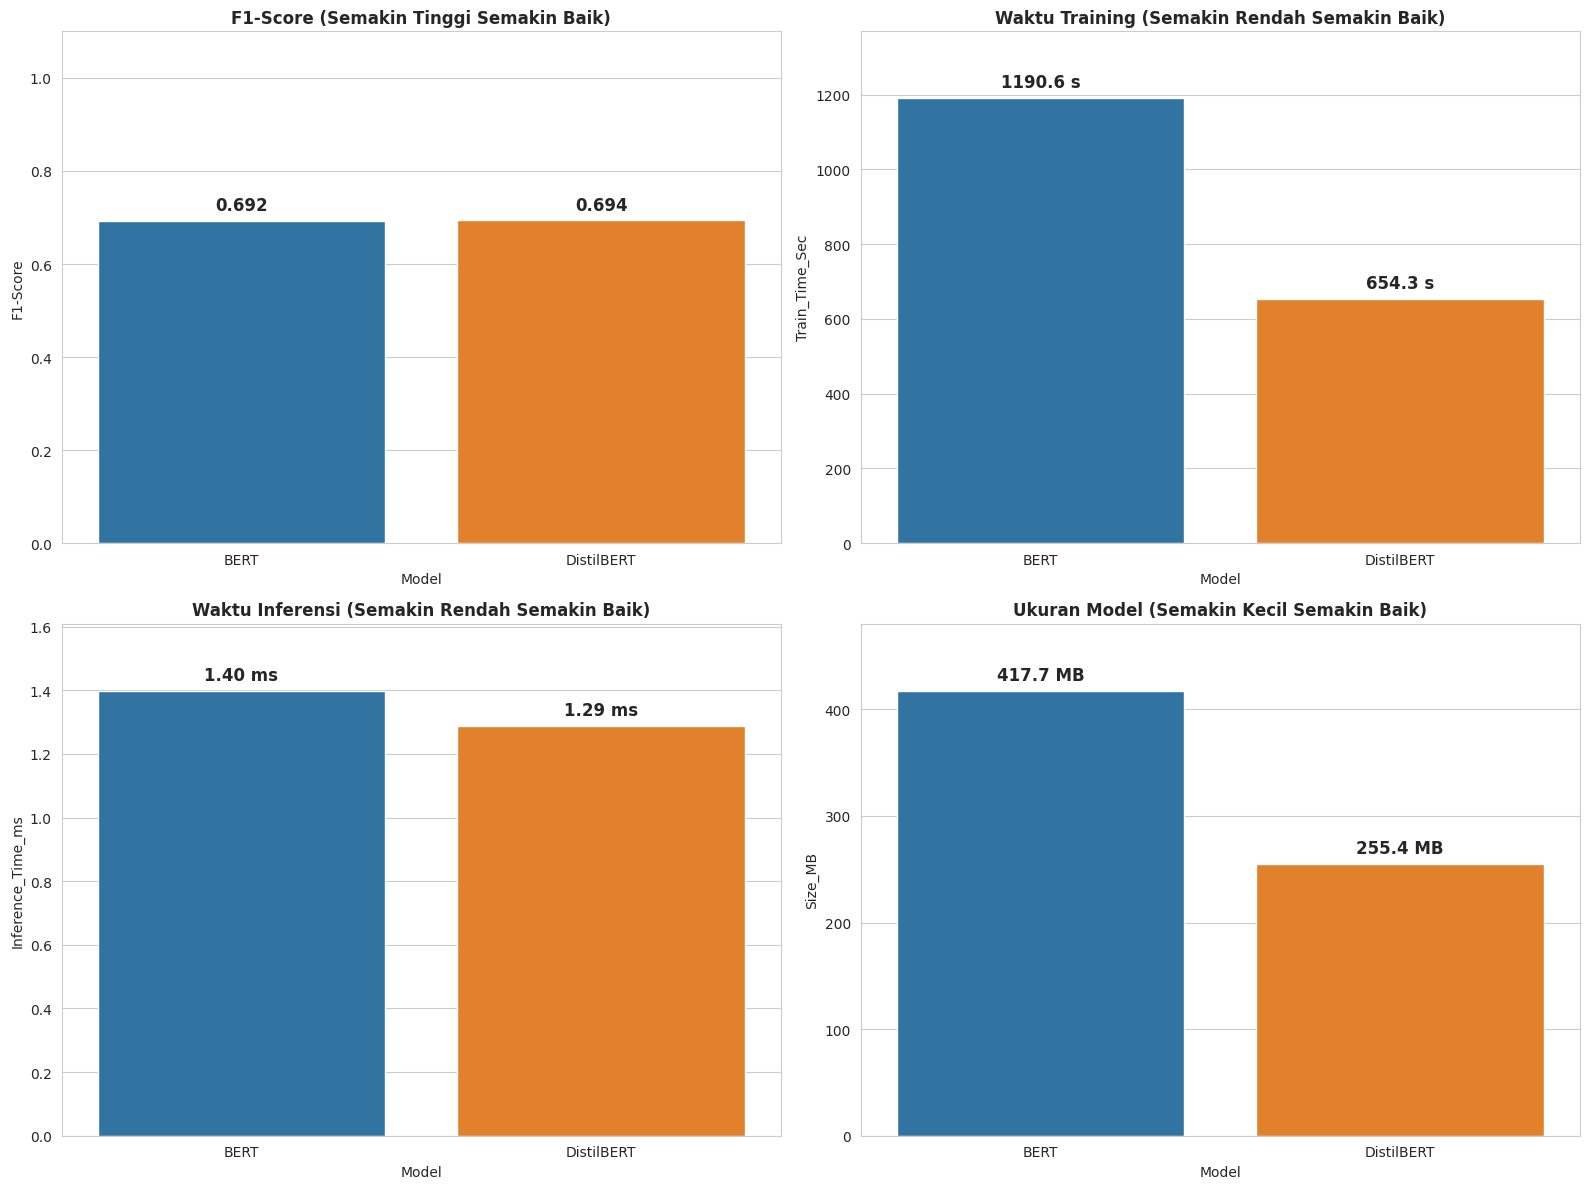

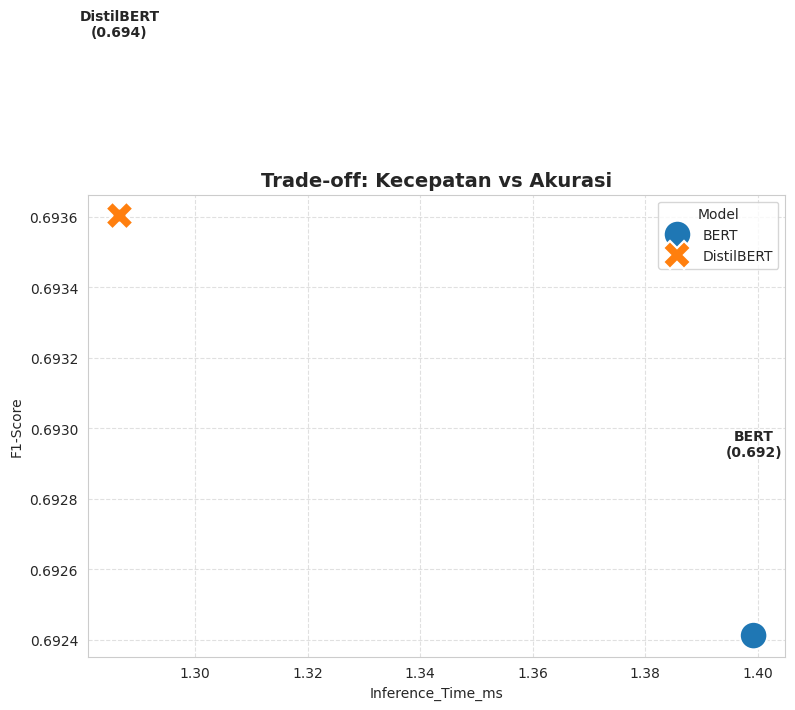

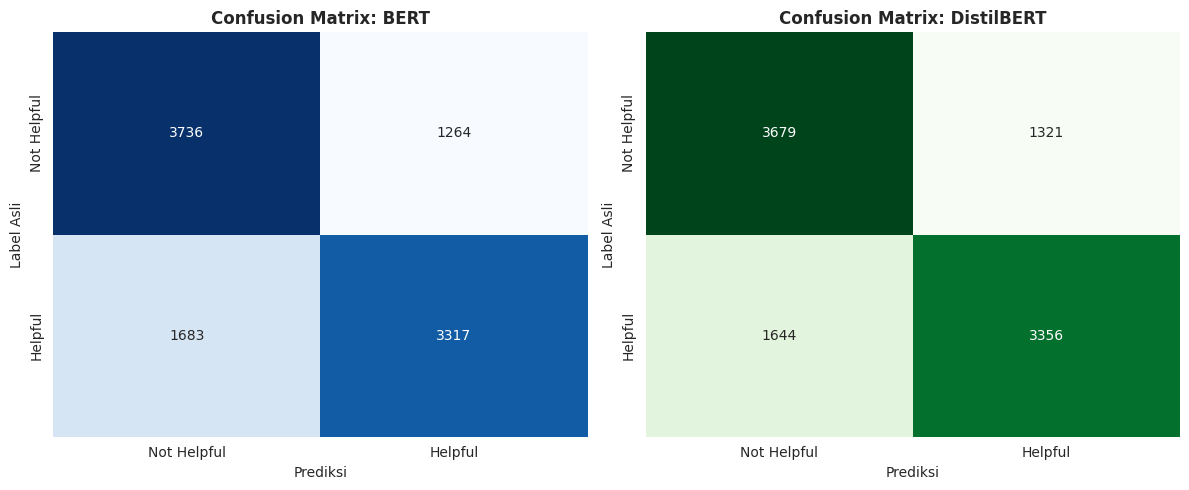

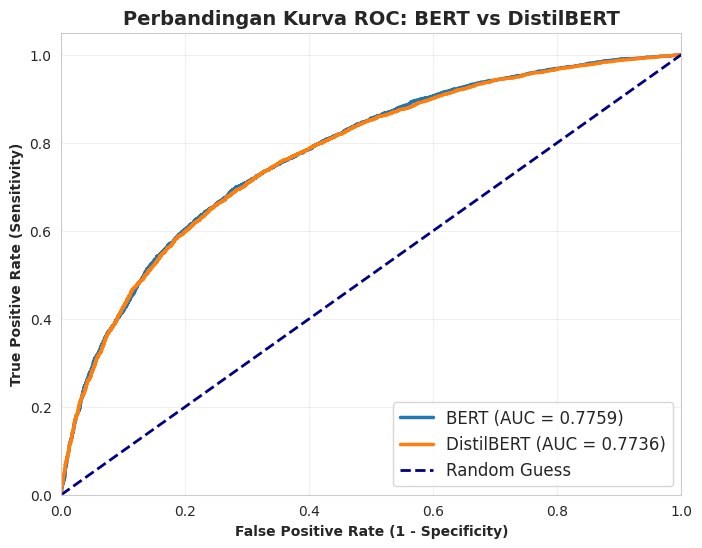

✅ AUC Score BERT: 0.7759
✅ AUC Score DistilBERT: 0.7736


In [ ]:
# ==========================================
# 1. SETUP & IMPORT
# ==========================================
import os
# Mencegah error memori terfragmentasi pada GPU
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

# Install library yang dibutuhkan (quiet mode)
!pip install transformers datasets scikit-learn pandas torch accelerate wordcloud -q

import pandas as pd
import numpy as np
import re
import torch
import time
import gc
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, roc_curve, auc
from transformers import (
    BertTokenizer, BertForSequenceClassification,
    DistilBertTokenizer, DistilBertForSequenceClassification,
    Trainer, TrainingArguments
)
from torch.utils.data import Dataset
import torch.nn.functional as F

# Cek Device (GPU/CPU)
torch.cuda.empty_cache()
gc.collect()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# ==========================================
# 2. LOAD DATA & SPLITTING
# ==========================================
filename = 'Beauty_dataset_50k.csv'
try:
    df = pd.read_csv(filename)
    print(f"✅ Data Loaded: {len(df)} baris")
except FileNotFoundError:
    raise ValueError(f"❌ File '{filename}' belum di-upload! Pastikan file CSV sudah ada di files Colab.")

# Cleaning Function
def clean_text(text):
    if not isinstance(text, str): return ""
    text = re.sub(r'<.*?>', '', text)       # Hapus HTML tags
    text = re.sub(r'http\S+', '', text)     # Hapus URL
    text = re.sub(r'\s+', ' ', text).strip() # Hapus spasi berlebih
    return text

df['clean_text'] = df['text'].apply(clean_text)

# Splitting Data
print("⏳ Membagi data training & testing...")
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label'],
    test_size=0.2, random_state=42, stratify=df['label']
)
print(f"✅ Siap Training: {len(X_train)} data latih, {len(X_test)} data uji")

# ==========================================
# 3. DATASET CLASS
# ==========================================
class ReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts.iloc[idx])
        label = self.labels.iloc[idx]
        encoding = self.tokenizer.encode_plus(
            text, add_special_tokens=True, max_length=self.max_len,
            padding='max_length', truncation=True, return_attention_mask=True, return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        'f1': f1_score(labels, predictions),
        'accuracy': accuracy_score(labels, predictions)
    }

# ==========================================
# 4. ENGINE TRAINING (Dengan Output Probabilitas untuk ROC)
# ==========================================
def train_and_evaluate(model_name, X_train, y_train, X_test, y_test):
    print(f"\n🚀 MEMULAI TRAINING: {model_name}...")

    # Bersihkan Memori GPU sebelum mulai
    torch.cuda.empty_cache()
    gc.collect()

    # Inisialisasi Model & Tokenizer
    if model_name == 'BERT':
        ckpt = 'bert-base-uncased'
        tokenizer = BertTokenizer.from_pretrained(ckpt)
        model = BertForSequenceClassification.from_pretrained(ckpt, num_labels=2)
    else:
        ckpt = 'distilbert-base-uncased'
        tokenizer = DistilBertTokenizer.from_pretrained(ckpt)
        model = DistilBertForSequenceClassification.from_pretrained(ckpt, num_labels=2)

    model.to(device)
    train_ds = ReviewDataset(X_train, y_train, tokenizer)
    test_ds = ReviewDataset(X_test, y_test, tokenizer)

    args = TrainingArguments(
        output_dir=f'./results_{model_name}',
        num_train_epochs=2,              # Epochs
        per_device_train_batch_size=16,  # Batch Size Training
        per_device_eval_batch_size=32,   # Batch Size Eval
        fp16=True if torch.cuda.is_available() else False, # Gunakan Mixed Precision jika ada GPU
        eval_strategy="epoch",
        save_strategy="no",              # Tidak perlu save checkpoint per epoch untuk hemat storage
        learning_rate=2e-5,
        report_to="none"
    )

    trainer = Trainer(
        model=model, args=args,
        train_dataset=train_ds, eval_dataset=test_ds,
        compute_metrics=compute_metrics
    )

    # 1. Training Loop
    start = time.time()
    trainer.train()
    train_time = time.time() - start
    print(f"✅ Training Selesai: {train_time:.2f} detik")

    # 2. Evaluasi Metrik Standar
    eval_res = trainer.evaluate()

    # 3. Hitung Ukuran Model (Real Memory Footprint)
    param_size = sum(p.nelement() * p.element_size() for p in model.parameters())
    buffer_size = sum(b.nelement() * b.element_size() for b in model.buffers())
    real_size_mb = (param_size + buffer_size) / 1024**2
    print(f"📊 Ukuran Model {model_name}: {real_size_mb:.2f} MB")

    # 4. Cek Kecepatan Inferensi (Pada sampel 1000 data)
    sample_text = X_test.iloc[:1000].tolist()
    model.eval()
    t0 = time.time()
    with torch.no_grad():
        inputs = tokenizer(sample_text, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
        _ = model(**inputs)
    infer_time_ms = ((time.time() - t0) * 1000) / 1000 # ms per 1000 samples / 1000 = ms/sample

    # 5. Full Prediction untuk Confusion Matrix & ROC Curve
    # trainer.predict() mengembalikan logits mentah
    preds_output = trainer.predict(test_ds)
    logits = preds_output.predictions
    labels = preds_output.label_ids

    # Konversi Logits ke Probabilitas menggunakan Softmax
    probs = F.softmax(torch.tensor(logits), dim=-1).numpy()
    probs_positive = probs[:, 1] # Ambil probabilitas untuk kelas positif (Helpful)

    # Prediksi label keras (0 atau 1)
    preds_labels = np.argmax(logits, axis=-1)
    cm = confusion_matrix(labels, preds_labels)

    # Bersihkan memori setelah selesai
    del model, tokenizer, trainer
    torch.cuda.empty_cache()

    return {
        'Model': model_name,
        'F1-Score': eval_res['eval_f1'],
        'Accuracy': eval_res['eval_accuracy'],
        'Train_Time_Sec': train_time,
        'Inference_Time_ms': infer_time_ms,
        'CM': cm,
        'Size_MB': round(real_size_mb, 2),
        'Probs': probs_positive, # Penting untuk ROC
        'True_Labels': labels    # Penting untuk ROC
    }

# ==========================================
# 5. EKSEKUSI & VISUALISASI
# ==========================================

# 1. Jalankan Eksperimen untuk Kedua Model
bert_res = train_and_evaluate('BERT', X_train, y_train, X_test, y_test)
distil_res = train_and_evaluate('DistilBERT', X_train, y_train, X_test, y_test)

# 2. Buat Dataframe Hasil (Kecuali data array besar)
results_df = pd.DataFrame([
    {k: v for k, v in bert_res.items() if k not in ['Probs', 'True_Labels', 'CM']},
    {k: v for k, v in distil_res.items() if k not in ['Probs', 'True_Labels', 'CM']}
])

print("\n=== RINGKASAN HASIL FINAL ===")
display(results_df)

# --- CONFIG VISUALISASI ---
sns.set_style("whitegrid")

# --- GRAFIK 1-4: Metrik Bar Charts ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# F1-Score
ax1 = sns.barplot(x='Model', y='F1-Score', data=results_df, palette=['#1f77b4', '#ff7f0e'], ax=axes[0,0])
axes[0,0].set_title('F1-Score (Semakin Tinggi Semakin Baik)', fontweight='bold')
axes[0,0].set_ylim(0, 1.1)
for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0, 5), textcoords='offset points')

# Waktu Training
ax2 = sns.barplot(x='Model', y='Train_Time_Sec', data=results_df, palette=['#1f77b4', '#ff7f0e'], ax=axes[0,1])
axes[0,1].set_title('Waktu Training (Semakin Rendah Semakin Baik)', fontweight='bold')
axes[0,1].set_ylim(0, results_df['Train_Time_Sec'].max() * 1.15)
for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.1f} s', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0, 5), textcoords='offset points')

# Waktu Inferensi
ax3 = sns.barplot(x='Model', y='Inference_Time_ms', data=results_df, palette=['#1f77b4', '#ff7f0e'], ax=axes[1,0])
axes[1,0].set_title('Waktu Inferensi (Semakin Rendah Semakin Baik)', fontweight='bold')
axes[1,0].set_ylim(0, results_df['Inference_Time_ms'].max() * 1.15)
for p in ax3.patches:
    ax3.annotate(f'{p.get_height():.2f} ms', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0, 5), textcoords='offset points')

# Ukuran Model
ax4 = sns.barplot(x='Model', y='Size_MB', data=results_df, palette=['#1f77b4', '#ff7f0e'], ax=axes[1,1])
axes[1,1].set_title('Ukuran Model (Semakin Kecil Semakin Baik)', fontweight='bold')
axes[1,1].set_ylim(0, results_df['Size_MB'].max() * 1.15)
for p in ax4.patches:
    ax4.annotate(f'{p.get_height():.1f} MB', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=12, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# --- GRAFIK 5: Trade-off Chart ---
plt.figure(figsize=(9, 6))
sns.scatterplot(data=results_df, x='Inference_Time_ms', y='F1-Score', hue='Model', style='Model', s=400, palette=['#1f77b4', '#ff7f0e'])
plt.title('Trade-off: Kecepatan vs Akurasi', fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
# Label pada titik scatter
for i in range(len(results_df)):
    plt.text(results_df.iloc[i]['Inference_Time_ms'], results_df.iloc[i]['F1-Score']+0.0005,
             f"{results_df.iloc[i]['Model']}\n({results_df.iloc[i]['F1-Score']:.3f})",
             fontweight='bold', ha='center', va='bottom')
plt.show()

# --- GRAFIK 6 & 7: Confusion Matrix ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# CM BERT
sns.heatmap(bert_res['CM'], annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Not Helpful', 'Helpful'], yticklabels=['Not Helpful', 'Helpful'])
axes[0].set_title('Confusion Matrix: BERT', fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Label Asli')

# CM DistilBERT
sns.heatmap(distil_res['CM'], annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Not Helpful', 'Helpful'], yticklabels=['Not Helpful', 'Helpful'])
axes[1].set_title('Confusion Matrix: DistilBERT', fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Label Asli')

plt.tight_layout()
plt.show()

#
# --- GRAFIK 8: ROC CURVE & AUC (Integrated) ---
plt.figure(figsize=(8, 6))

# 1. Hitung & Plot ROC BERT
fpr_bert, tpr_bert, _ = roc_curve(bert_res['True_Labels'], bert_res['Probs'])
auc_bert = auc(fpr_bert, tpr_bert)
plt.plot(fpr_bert, tpr_bert, label=f'BERT (AUC = {auc_bert:.4f})', color='#1f77b4', lw=2.5)

# 2. Hitung & Plot ROC DistilBERT
fpr_distil, tpr_distil, _ = roc_curve(distil_res['True_Labels'], distil_res['Probs'])
auc_distil = auc(fpr_distil, tpr_distil)
plt.plot(fpr_distil, tpr_distil, label=f'DistilBERT (AUC = {auc_distil:.4f})', color='#ff7f0e', lw=2.5)

# 3. Garis Diagonal (Random Guessing Line)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

# 4. Styling
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
plt.title('Perbandingan Kurva ROC: BERT vs DistilBERT', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

print(f"✅ AUC Score BERT: {auc_bert:.4f}")
print(f"✅ AUC Score DistilBERT: {auc_distil:.4f}")

In [ ]:
!nvidia-smi

Sun Dec 21 10:35:28 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P0             27W /   70W |    1102MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----